<div align="center">

# 🧬 Computer Assignment 2: Genetic Algorithm  
## 🎵 Melody Reconstruction using Evolution

**Course:** Artificial Intelligence   
<br>


</div>

---


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import soundfile as sf
import scipy.io.wavfile as wavfile
import random


## 🎧 Part 1: Melody Extraction

Before our Genetic Algorithm can start evolving, it needs a Target Sequence to compare itself against. 

The code provided below takes an audio file (`.wav`), cuts it into small chunks based on the `note_duration`, and uses the **Fast Fourier Transform (FFT)** to find the dominant frequency (pitch) in each chunk. 
- A frequency of `0` means silence.
- Other numbers (e.g., `440`, `262`) represent musical notes.




### Extracting Frequencies from Audio


In [2]:
def extract_frequencies_from_wav(filename, note_duration, sample_rate=44100):
    sr, data = wavfile.read(filename)
    
    # اگر استریو بود، تبدیل به مونو (میانگین دو کانال)
    if len(data.shape) > 1:
        data = np.mean(data, axis=1).astype(data.dtype)
    
    chunk_samples = int(sr * note_duration)
    extracted_freqs = []
    num_chunks = len(data) // chunk_samples
    max_amplitude = np.max(np.abs(data))
    silence_threshold = max_amplitude * 0.05   

    for i in range(num_chunks):
        start = i * chunk_samples
        end = start + chunk_samples
        chunk = data[start:end]
        
        if np.max(np.abs(chunk)) < silence_threshold:
            extracted_freqs.append(0)
            continue
            
        mid_start = int(0.20 * len(chunk))
        mid_end = int(0.80 * len(chunk))
        focus_chunk = chunk[mid_start:mid_end]
        
        window = np.hanning(len(focus_chunk))
        windowed_chunk = focus_chunk * window
        
        N_padded = sample_rate * 2 
        
        fft_result = np.fft.fft(windowed_chunk, n=N_padded)
        freqs = np.fft.fftfreq(N_padded, 1/sr)
        
        pos_mask = (freqs > 20) & (freqs < 2000)
        fft_result = np.abs(fft_result[pos_mask])
        freqs = freqs[pos_mask]
        
        if len(fft_result) == 0:
            extracted_freqs.append(0)
            continue
            
        peak_idx = np.argmax(fft_result)
        peak_freq = freqs[peak_idx]
        
        extracted_freqs.append(int(round(peak_freq)))

    while extracted_freqs and extracted_freqs[-1] == 0:
        extracted_freqs.pop()

    return extracted_freqs

if __name__ == "__main__":

    path1 = "musics/got_target.wav"
    path2 = "musics/interstellar_target.wav"
    path3 = "musics/harry_potter_target.wav"
    path4 = "musics/bella_ciao_target.wav"
    path5 = "musics/mario_target.wav"
    path6 = "musics/pink_panther_target.wav"
    path7 = "musics/fur_elise_target.wav"
    path8 = "musics/swan_lake_target.wav"
    path9 = "musics/squid_game_target.wav"
    path10 = "musics/waltz.wav"
 
    songs = {
        path1: 0.25,
        path2: 0.25,
        path3: 0.25,
        path4: 0.25,
        path5: 0.20,
        path6: 0.25,
        path7: 0.30,
        path8: 0.30,
        path9: 0.30,
        path10:0.25,

    }
    test_file = path10
    duration = songs[test_file]
    target_frequencies = extract_frequencies_from_wav(test_file, note_duration=duration)
    # print(f"Target Array Length: {len(target_frequencies)}")
    # print(target_frequencies)


# <span style="color: #3498db;">Genetic Algorithm</span>

---
## 🧬 Part 2: Implementing the Genetic Algorithm Class

For this assignment, you will implement the core components of a Genetic Algorithm within a structured class. This approach helps in organizing the evolutionary process.

A `GeneticAlgorithm` class will manage the population and the evolutionary steps. You will need to implement the methods for initialization, fitness calculation, selection, crossover, and mutation.


<div style="font-size: 1.2em; font-weight: bold; margin-bottom: 5px;">⚠️ Important Note on Performance:</div>  
Using <b>NumPy arrays</b> for all operations is crucial for efficiency. Vectorized operations are significantly faster than standard Python loops. Aim to implement your logic using NumPy functions wherever possible.
</div>


In [7]:
class BestGeneticAlgorithm:
    def __init__(self, target, pop_size=200, generations=500, mutation_rate=0.01):
        self.target = np.array(target)
        self.pop_size = pop_size
        self.generations = generations
        self.mutation_rate = mutation_rate
        self.chrom_length = len(target)
        
        # محدوده فرکانس‌های منطقی بر اساس نت‌های موسیقی
        self.min_possible = 0
        self.max_possible = 988  # فرکانس نت B6 در لیست شما
        
        # مقداردهی اولیه جمعیت و متغیرهای ذخیره‌سازی
        self.population = self._init_population()
        self.best_chrom = None
        self.best_history = []

    def _init_population(self):
        """ساخت جمعیت اولیه به صورت کاملاً تصادفی"""
        return np.random.randint(self.min_possible, self.max_possible + 1, 
                                 size=(self.pop_size, self.chrom_length))

    def _calculate_fitness(self, method='combined'):
        """
        محاسبه فیتنس با ۳ روش مختلف طبق خواسته پروژه
        """
        pop = np.array(self.population)
        target = np.array(self.target)
        
        # روش اول: روش ترکیبی و هوشمندانه شما (پیش‌فرض)
        if method == 'combined':
            mae = np.mean(np.abs(pop - target), axis=1)
            exact_counts = np.sum(pop == target, axis=1)
            fitness = 0.7 * (exact_counts / self.chrom_length) + 0.3 * np.exp(-mae / 10)
            return fitness
            
        # روش دوم: معکوس خطای میانگین مربعات (MSE)
        elif method == 'mse_inverse':
            mse = np.mean((pop - target) ** 2, axis=1)
            fitness = 1.0 / (mse + 1e-6)
            return fitness
            
        # روش سوم: شباهت کسینوسی (Cosine Similarity)
        elif method == 'cosine_similarity':
            dot_product = np.sum(pop * target, axis=1)
            norm_pop = np.linalg.norm(pop, axis=1)
            norm_target = np.linalg.norm(target)
            cosine_sim = dot_product / (norm_pop * norm_target + 1e-6)
            return cosine_sim
            
        else:
            raise ValueError("Method not recognized! Choose from 'combined', 'mse_inverse', or 'cosine_similarity'")

    def _selection(self, num_parents, method='roulette_wheel', tournament_size=3):
        """
        انتخاب والدین با ۳ روش مختلف طبق خواسته پروژه
        """
        # فرستادن پارامتر combined برای محاسبه فیتنس اصلی
        fitness = self._calculate_fitness(method='combined')
        
        if method == 'roulette_wheel':
            fitness_sum = fitness.sum()
            probs = np.ones(self.pop_size) / self.pop_size if fitness_sum == 0 else fitness / fitness_sum
            indices = np.random.choice(self.pop_size, num_parents, p=probs)
            return self.population[indices]
            
        elif method == 'tournament':
            selected_indices = []
            for _ in range(num_parents):
                fighter_indices = np.random.choice(self.pop_size, size=tournament_size, replace=False)
                best_fighter = fighter_indices[np.argmax(fitness[fighter_indices])]
                selected_indices.append(best_fighter)
            return self.population[selected_indices]
            
        elif method == 'rank':
            ranks = np.argsort(np.argsort(fitness))
            rank_sum = np.sum(ranks)
            probs = np.ones(self.pop_size) / self.pop_size if rank_sum == 0 else ranks / rank_sum
            indices = np.random.choice(self.pop_size, num_parents, p=probs)
            return self.population[indices]
        else:
            raise ValueError("Method not recognized! Choose from 'roulette_wheel', 'tournament', or 'rank'")

    def _crossover(self, parents, offspring_size, method='single_point'):
        """
        ترکیب کروموزوم‌ها با ۳ روش مختلف طبق خواسته پروژه
        """
        if isinstance(offspring_size, tuple):
            num_offspring = offspring_size[0]
            chrom_length = offspring_size[1]
        else:
            num_offspring = offspring_size
            chrom_length = self.chrom_length

        offspring = np.zeros((num_offspring, chrom_length))
        
        for i in range(0, num_offspring, 2):
            p1 = parents[i % len(parents)]
            p2 = parents[(i + 1) % len(parents)]
            
            if method == 'single_point':
                point = np.random.randint(1, chrom_length)
                offspring[i] = np.concatenate([p1[:point], p2[point:]])
                if i + 1 < num_offspring:
                    offspring[i + 1] = np.concatenate([p2[:point], p1[point:]])
            
            elif method == 'two_point':
                points = sorted(np.random.choice(range(1, chrom_length), size=2, replace=False))
                pt1, pt2 = points[0], points[1]
                offspring[i] = np.concatenate([p1[:pt1], p2[pt1:pt2], p1[pt2:]])
                if i + 1 < num_offspring:
                    offspring[i + 1] = np.concatenate([p2[:pt1], p1[pt1:pt2], p2[pt2:]])
            
            elif method == 'uniform':
                mask = np.random.rand(chrom_length) < 0.5
                offspring[i] = np.where(mask, p1, p2)
                if i + 1 < num_offspring:
                    offspring[i + 1] = np.where(mask, p2, p1)
            else:
                raise ValueError("Method not recognized! Choose from 'single_point', 'two_point', or 'uniform'")
                
        return offspring

    def _mutation(self, offspring):
        """اعمال جهش بر روی فرزندان تولید شده"""
        mutated = offspring.copy()
        for i in range(mutated.shape[0]):
            for j in range(mutated.shape[1]):
                if np.random.rand() < self.mutation_rate:
                    mutated[i, j] = np.random.randint(self.min_possible, self.max_possible + 1)
        return mutated

    def run(self):
        """حلقه اصلی الگوریتم ژنتیک (تکامل نسل‌ها)"""
        elite_count = max(1, self.pop_size // 10) # حفظ ۱۰ درصد برتر به عنوان نخبه
        
        for gen in range(self.generations):
            # ۱. محاسبه فیتنس با روش اصلی ترکیبی شما
            fitness = self._calculate_fitness(method='combined')
            
            # ۲. پیدا کردن و ذخیره بهترین فرد این نسل
            best_idx = np.argmax(fitness)
            best_fit = fitness[best_idx]
            best_individual = self.population[best_idx].copy()
            
            mae_now = np.mean(np.abs(best_individual - self.target))
            self.best_history.append(best_fit)
            
            # بروزرسانی بهترین کروموزوم کل تاریخچه بر اساس کمترین خطا
            if self.best_chrom is None or mae_now < np.mean(np.abs(self.best_chrom - self.target)):
                self.best_chrom = best_individual.copy()
            
            if gen % 50 == 0 or gen == self.generations - 1:
                print(f"Gen {gen}: Best Fitness={best_fit:.4f}, MAE={mae_now:.1f}Hz")
            
            # ۳. انتخاب والدین (با روش پیش‌فرض چرخ رولت)
            num_parents = self.pop_size - elite_count
            parents = self._selection(num_parents, method='roulette_wheel')
            
            # ۴. انجام عملیات کراس‌اوور (با روش پیش‌فرض تک‌نقطه‌ای)
            offspring = self._crossover(parents, offspring_size=(num_parents, self.chrom_length), method='single_point')
            
            # ۵. اعمال جهش تصادفی روی فرزندان
            offspring = self._mutation(offspring)
            
            # ۶. جایگزینی نسل قدیم با نسل جدید (ترکیب نخبگان و فرزندان تازه)
            elite_indices = np.argsort(fitness)[-elite_count:]
            elites = self.population[elite_indices].copy()
            self.population = np.vstack([elites, offspring])
        
        # محاسبه خطای نهایی بهترین کروموزوم یافت‌شده
        final_mae = np.mean(np.abs(self.best_chrom - self.target))
        
        # برگرداندن ۳ پارامتر دقیقاً مطابق با خواسته کدهای بعدی نوت‌بوک شما
        return self.best_chrom, final_mae, self.best_history

---
## Part 3: Visualization

Numbers are good, but plots are better! 
In this section, you need to plot your Best Chromosome against the Target Frequencies. 
Use a line plot or a step plot. This visual overlap will quickly show you which notes your algorithm successfully learned and which ones it missed.


Gen 0: Best Fitness=0.0194, MAE=261.0Hz
Gen 50: Best Fitness=0.1750, MAE=184.1Hz
Gen 100: Best Fitness=0.2042, MAE=111.6Hz
Gen 150: Best Fitness=0.2431, MAE=86.2Hz
Gen 200: Best Fitness=0.2630, MAE=64.1Hz
Gen 250: Best Fitness=0.2778, MAE=39.8Hz
Gen 300: Best Fitness=0.3235, MAE=26.1Hz
Gen 350: Best Fitness=0.3685, MAE=16.5Hz
Gen 400: Best Fitness=0.4279, MAE=12.3Hz
Gen 450: Best Fitness=0.4798, MAE=8.4Hz
Gen 500: Best Fitness=0.5221, MAE=5.6Hz
Gen 550: Best Fitness=0.5573, MAE=3.7Hz
Gen 600: Best Fitness=0.5732, MAE=3.4Hz
Gen 650: Best Fitness=0.6161, MAE=2.8Hz
Gen 700: Best Fitness=0.6408, MAE=2.1Hz
Gen 750: Best Fitness=0.6577, MAE=1.8Hz
Gen 799: Best Fitness=0.6803, MAE=1.7Hz
نتیجه نهایی:
   میانگین خطای مطلق (MAE): 1.7 Hz
   نت‌های کاملاً دقیق: 44/72
   نت‌های با خطای <50Hz: 72/72


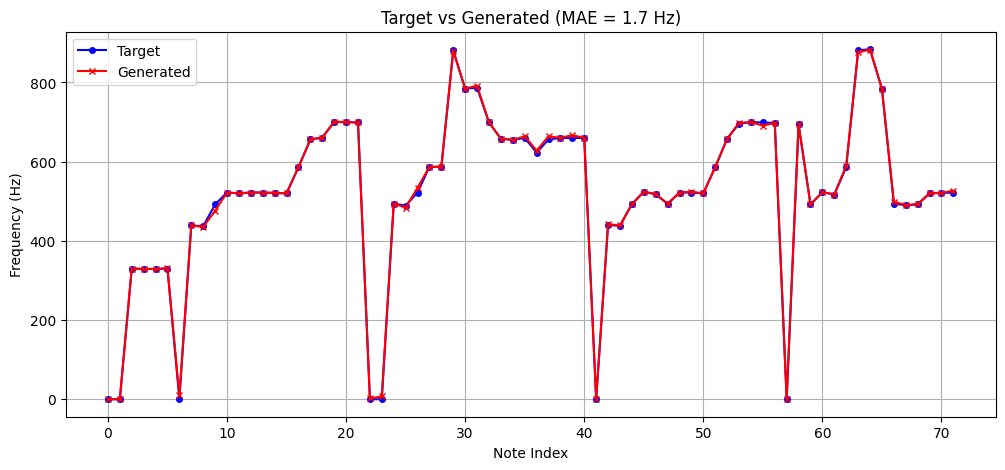

 نتایج بعد از گرد کردن به نت‌های موسیقی:
   نت‌های کاملاً دقیق: 71/72 (98.6%)
   MAE بعد از گرد کردن: 0.4 Hz


In [8]:
# Add legends, title, and labels to make it professional.


ga = BestGeneticAlgorithm(target_frequencies, pop_size=400, generations=800, mutation_rate=0.005)
best_chromosome, final_mae, history = ga.run()

print("نتیجه نهایی:")
print(f"   میانگین خطای مطلق (MAE): {final_mae:.1f} Hz")
print(f"   نت‌های کاملاً دقیق: {np.sum(best_chromosome == target_frequencies)}/{len(target_frequencies)}")
print(f"   نت‌های با خطای <50Hz: {np.sum(np.abs(best_chromosome - target_frequencies) < 50)}/{len(target_frequencies)}")
 
# رسم نمودار مقایسه Target و Generated
plt.figure(figsize=(12, 5))
plt.plot(target_frequencies, 'b-o', label='Target', markersize=4)
plt.plot(best_chromosome, 'r-x', label='Generated', markersize=4)
plt.xlabel('Note Index')
plt.ylabel('Frequency (Hz)')
plt.title(f'Target vs Generated (MAE = {final_mae:.1f} Hz)')
plt.legend()
plt.grid(True)
plt.show()

# فرکانس‌های نت‌های موسیقی (نت‌های سفید پیانو از C3 تا B6)
note_frequencies = [0, 262, 277, 294, 311, 330, 349, 370, 392, 415, 440, 466, 494, 
                    523, 554, 587, 622, 659, 698, 740, 784, 831, 880, 932, 988]

def round_to_note(freq):
    """گرد کردن فرکانس به نزدیک‌ترین نت موسیقی"""
    if freq == 0:
        return 0
    return min(note_frequencies, key=lambda x: abs(x - freq))

# اعمال گرد کردن روی target و best_chromosome
target_rounded = [round_to_note(f) for f in target_frequencies]
best_rounded = [round_to_note(f) for f in best_chromosome]

# محاسبه نتایج جدید
exact_after_rounding = np.sum(np.array(target_rounded) == np.array(best_rounded))
mae_after_rounding = np.mean(np.abs(np.array(best_rounded) - np.array(target_rounded)))

print(" نتایج بعد از گرد کردن به نت‌های موسیقی:")
print(f"   نت‌های کاملاً دقیق: {exact_after_rounding}/{len(target_frequencies)} ({exact_after_rounding/len(target_frequencies)*100:.1f}%)")
print(f"   MAE بعد از گرد کردن: {mae_after_rounding:.1f} Hz")
 

---
## 🎵 Part 4: The Ultimate Test (Listen to Your Algorithm)

Has your Genetic Algorithm learned to play music? Let's find out!
The function below takes your array of frequencies and synthesizes it into a real audio file using sine waves, harmonics, vibrato, and echo effects.

**Instructions:**
1. Run the synthesis function.
2. Pass your `best_chromosome` to this function.
3. Open the generated `.wav` file and listen to it! 
*(Make sure to use the exact same `note_duration` that was used to extract the target frequencies).*


In [ ]:
from scipy.io import wavfile

def frequencies_to_melody(frequencies, output_filename="ai_melody_clean.wav", note_duration=0.25, sample_rate=44100):
    """Generates a clean, standard synth sound (Good for checking accuracy)."""
    print(f"Synthesizing Clean Audio: {output_filename}")
    audio_signal = []    
    t = np.linspace(0, note_duration, int(sample_rate * note_duration), False)
    envelope = np.ones_like(t)
    attack_len = int(0.05 * len(t))
    envelope[:attack_len] = np.linspace(0, 1, attack_len)
    envelope[attack_len:] = np.exp(-3.5 * np.linspace(0, 1, len(t) - attack_len))
    
    for freq in frequencies:
        if freq > 10: 
            wave = np.sin(2 * np.pi * freq * t)              
            wave += 0.5 * np.sin(2 * np.pi * (freq * 2) * t) 
            wave += 0.25 * np.sin(2 * np.pi * (freq * 3) * t)  
            wave = wave * envelope
        else:
            wave = np.zeros_like(t)
        audio_signal.extend(wave)
        
    audio_signal = np.array(audio_signal)
    max_val = np.max(np.abs(audio_signal))
    if max_val > 0:
        audio_signal = audio_signal / max_val        
    fade_out_len = int(sample_rate * 0.1)
    if len(audio_signal) > fade_out_len:
        audio_signal[-fade_out_len:] *= np.linspace(1, 0, fade_out_len)
    audio_int16 = np.int16(audio_signal * 32767 * 0.8)
    wavfile.write(output_filename, sample_rate, audio_int16)

def frequencies_to_melody_ultimate(frequencies, output_filename="ai_melody_ultimate.wav", note_duration=0.25, sample_rate=44100):
    """Generates a rich, professional sound with Vibrato and Echo (The Grand Prize!)."""
    print(f"Synthesizing Ultimate Audio: {output_filename}")
    audio_signal = []
    t = np.linspace(0, note_duration, int(sample_rate * note_duration), False)
    
    envelope = np.ones_like(t)
    attack = int(0.05 * len(t))
    envelope[:attack] = np.linspace(0, 1, attack)
    envelope[attack:] = np.exp(-4 * np.linspace(0, 1, len(t) - attack))
    
    for freq in frequencies:
        if freq > 10:
            vibrato_rate = 5.0 
            vibrato_depth = 0.01 * freq 
            vibrato = np.sin(2 * np.pi * vibrato_rate * t) * vibrato_depth
            
            wave = np.sin(2 * np.pi * (freq + vibrato) * t)                 
            wave += 0.4 * np.sin(2 * np.pi * (freq * 2 + vibrato) * t)      
            wave += 0.2 * np.sin(2 * np.pi * (freq * 3 + vibrato) * t)      
            wave = wave * envelope
        else:
            wave = np.zeros_like(t)
        audio_signal.extend(wave)
        
    audio_signal = np.array(audio_signal)
    
    delay_samples = int(sample_rate * 0.3) 
    echo_signal = np.zeros(len(audio_signal) + delay_samples)
    echo_signal[:len(audio_signal)] = audio_signal
    echo_signal[delay_samples:] += audio_signal * 0.35 
    
    max_val = np.max(np.abs(echo_signal))
    if max_val > 0:
        echo_signal = echo_signal / max_val
        
    audio_int16 = np.int16(echo_signal * 32767 * 0.8)
    wavfile.write(output_filename, sample_rate, audio_int16)
    print("Done!\n")


# ==========================================
# Here we use the note_duration you defined earlier.


NOTE_DURATION = 0.25

frequencies_to_melody(best_chromosome, "my_ai_melody_clean.wav", note_duration=NOTE_DURATION)
frequencies_to_melody_ultimate(best_chromosome, "my_ai_melody_ultimate.wav", note_duration=NOTE_DURATION)


Synthesizing Clean Audio: my_ai_melody_clean.wav
Synthesizing Ultimate Audio: my_ai_melody_ultimate.wav
Done!

